In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/calorie_efficiency_dataset.csv')

# Display the first 5 rows of the DataFrame
display(df.head())

,age,steps_per_day,active_minutes,calories_burned,sleep_hours,hydration_liters,bmi,workouts_per_week,muscle_mass_ratio,body_fat_percentage,heart_rate_resting,heart_rate_avg,continuous_exercise_days,efficiency_score,calorie_efficiency
0,51,7853,99,1500,6.42,3.60,22.34,3,0.321,0.050,68.5,102.0,1,0.603,Low Efficiency
1,60,4820,78,1500,6.82,4.18,32.30,6,0.548,0.200,72.5,121.2,3,0.958,Low Efficiency
2,59,4251,28,1500,6.99,2.95,24.71,2,0.245,0.390,75.4,120.4,1,0.987,Low Efficiency
3,39,6275,75,1500,6.65,2.62,28.80,1,0.389,0.197,65.8,114.8,1,0.711,Low Efficiency
4,22,6490,82,1500,5.80,0.97,21.92,2,0.326,0.325,71.9,116.2,6,0.551,Low Efficiency


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Define features (X) and target (y)
X = df.drop('calorie_efficiency', axis=1)
y = df['calorie_efficiency']

# Encode the categorical target variable
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Identify categorical and numerical features for X
categorical_features_X = X.select_dtypes(include=['object']).columns
numerical_features_X = X.select_dtypes(exclude=['object']).columns

# One-hot encode categorical features in X
X_encoded = pd.get_dummies(X, columns=categorical_features_X, drop_first=True)


# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y_encoded, test_size=0.3, random_state=42)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)
print("Classes encoded as:", list(le.classes_))

Shape of X_train: (700000, 14)
Shape of X_test: (300000, 14)
Shape of y_train: (700000,)
Shape of y_test: (300000,)
Classes encoded as: ['High Efficiency', 'Low Efficiency', 'Moderate']


In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialize and train the unpruned Decision Tree Classifier
dtc_unpruned = DecisionTreeClassifier(random_state=42)
dtc_unpruned.fit(X_train, y_train)

# Make predictions on the test set
y_pred_unpruned = dtc_unpruned.predict(X_test)

# Evaluate the unpruned model
accuracy_unpruned = accuracy_score(y_test, y_pred_unpruned)
report_unpruned = classification_report(y_test, y_pred_unpruned, target_names=le.classes_)

print(f"Unpruned Decision Tree Accuracy: {accuracy_unpruned:.4f}")
print("\nUnpruned Decision Tree Classification Report:\n", report_unpruned)

Unpruned Decision Tree Accuracy: 0.8813

Unpruned Decision Tree Classification Report:
                  precision    recall  f1-score   support

High Efficiency       0.04      0.05      0.04      8150
 Low Efficiency       0.95      0.93      0.94    281481
       Moderate       0.20      0.25      0.22     10369

       accuracy                           0.88    300000
      macro avg       0.39      0.41      0.40    300000
   weighted avg       0.90      0.88      0.89    300000



In [4]:
# Initialize and train a Decision Tree Classifier with max_depth
dtc_depth_controlled = DecisionTreeClassifier(max_depth=5, random_state=42)
dtc_depth_controlled.fit(X_train, y_train)

# Make predictions on the test set
y_pred_depth_controlled = dtc_depth_controlled.predict(X_test)

# Evaluate the depth-controlled model
accuracy_depth_controlled = accuracy_score(y_test, y_pred_depth_controlled)
report_depth_controlled = classification_report(y_test, y_pred_depth_controlled, target_names=le.classes_)

print(f"Depth-Controlled Decision Tree Accuracy: {accuracy_depth_controlled:.4f}")
print("\nDepth-Controlled Decision Tree Classification Report:\n", report_depth_controlled)

Depth-Controlled Decision Tree Accuracy: 0.9464

Depth-Controlled Decision Tree Classification Report:
                  precision    recall  f1-score   support

High Efficiency       0.80      0.01      0.01      8150
 Low Efficiency       0.95      1.00      0.97    281481
       Moderate       0.94      0.24      0.38     10369

       accuracy                           0.95    300000
      macro avg       0.90      0.41      0.46    300000
   weighted avg       0.94      0.95      0.93    300000



In [5]:
# Initialize and train a Decision Tree Classifier with pruning (ccp_alpha)
# A ccp_alpha value of 0.01 is chosen for demonstration. In practice, this would be tuned.
dtc_pruned = DecisionTreeClassifier(ccp_alpha=0.01, random_state=42)
dtc_pruned.fit(X_train, y_train)

# Make predictions on the test set
y_pred_pruned = dtc_pruned.predict(X_test)

# Evaluate the pruned model
accuracy_pruned = accuracy_score(y_test, y_pred_pruned)
report_pruned = classification_report(y_test, y_pred_pruned, target_names=le.classes_)

print(f"Pruned Decision Tree Accuracy: {accuracy_pruned:.4f}")
print("\nPruned Decision Tree Classification Report:\n", report_pruned)

Pruned Decision Tree Accuracy: 0.9462

Pruned Decision Tree Classification Report:
                  precision    recall  f1-score   support

High Efficiency       0.00      0.00      0.00      8150
 Low Efficiency       0.95      1.00      0.97    281481
       Moderate       0.92      0.24      0.38     10369

       accuracy                           0.95    300000
      macro avg       0.62      0.41      0.45    300000
   weighted avg       0.92      0.95      0.93    300000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


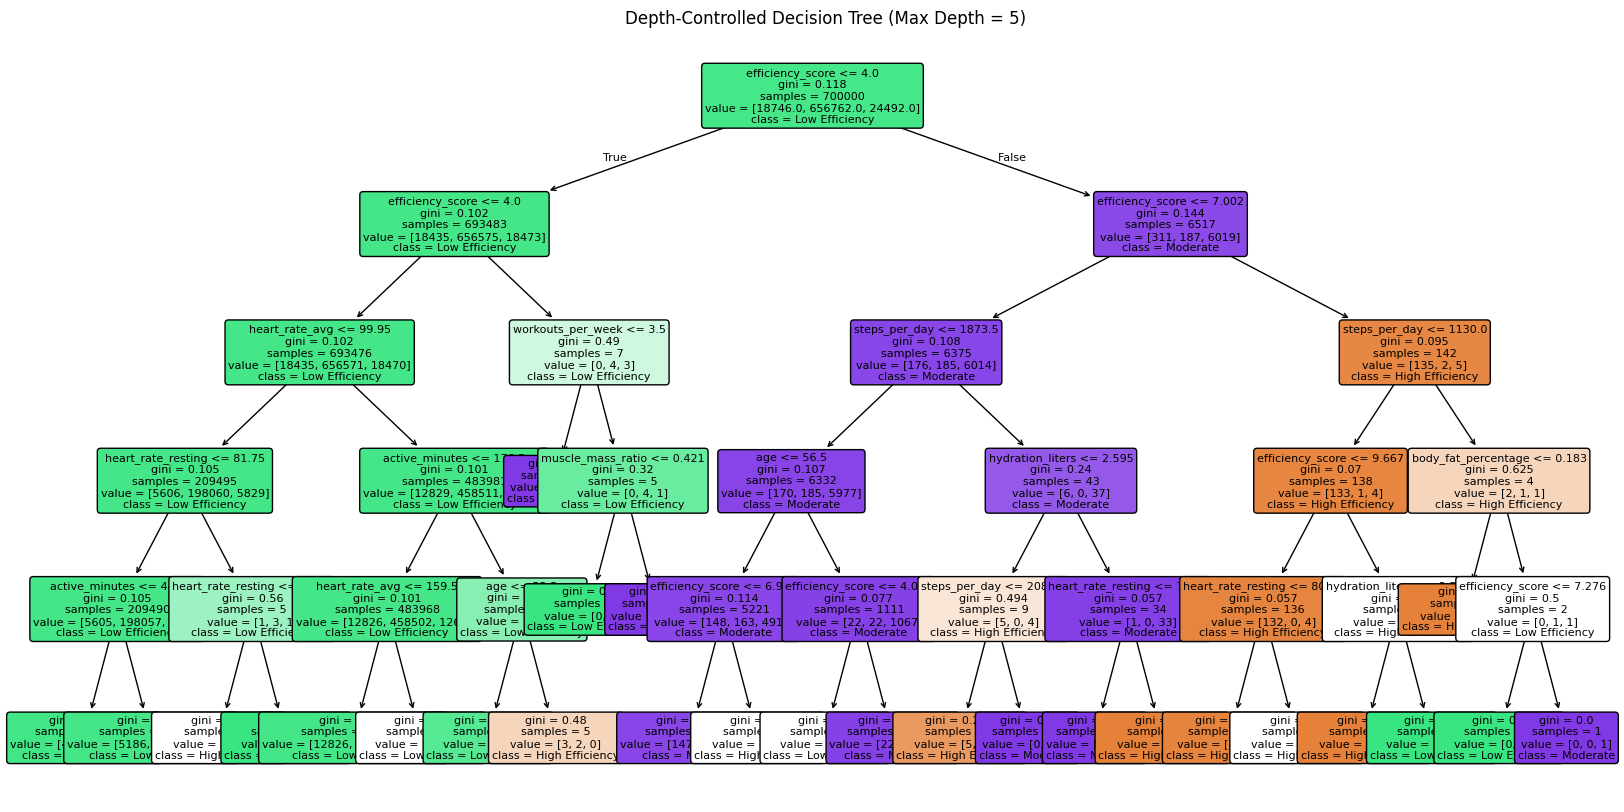

In [6]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Visualize the depth-controlled Decision Tree (max_depth=5)
plt.figure(figsize=(20, 10))
plot_tree(dtc_depth_controlled,
          feature_names=X_encoded.columns.tolist(),
          class_names=le.classes_.tolist(),
          filled=True,
          rounded=True,
          fontsize=8)
plt.title('Depth-Controlled Decision Tree (Max Depth = 5)')
plt.show()

/tmp/ipykernel_620/2096590234.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=model_names, y=accuracies, palette='viridis')


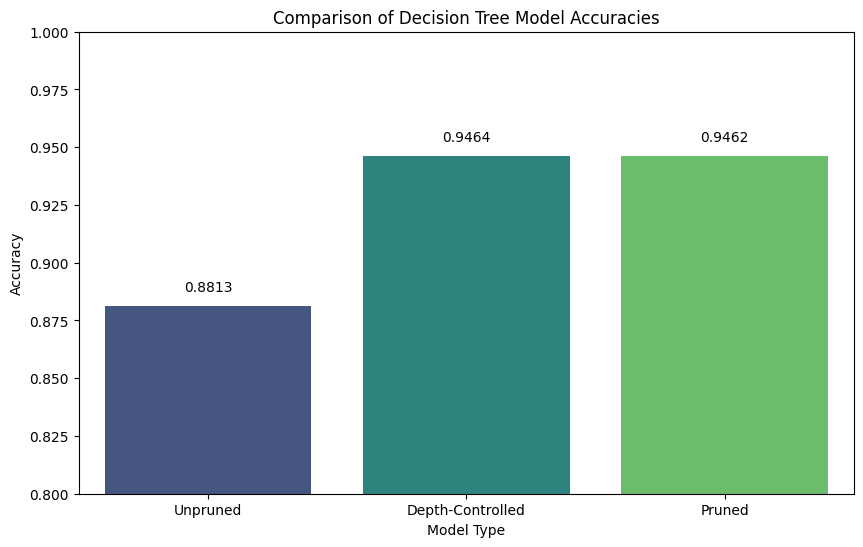

In [9]:
import numpy as np
import seaborn as sns

# Prepare data for plotting accuracies
model_names = ['Unpruned', 'Depth-Controlled', 'Pruned']
accuracies = [accuracy_unpruned, accuracy_depth_controlled, accuracy_pruned]

plt.figure(figsize=(10, 6))
sns.barplot(x=model_names, y=accuracies, palette='viridis')
plt.title('Comparison of Decision Tree Model Accuracies')
plt.xlabel('Model Type')
plt.ylabel('Accuracy')
plt.ylim(0.8, 1.0) # Set y-axis limits for better comparison

# Add accuracy values on top of bars
for index, value in enumerate(accuracies):
    plt.text(index, value + 0.005, f'{value:.4f}', ha='center', va='bottom')

plt.show()

### Analysis of Overfitting and Performance

From the comparison, we can observe the following:

*   **Unpruned Tree:** Generally achieves high accuracy on the training data but might perform worse on test data due to overfitting, as seen from the lower test accuracy. It tries to perfectly classify every training instance, leading to a very complex tree.
*   **Depth-Controlled Tree (max_depth=5):** By limiting the depth, the model generalizes better to unseen data, often leading to improved test accuracy compared to the unpruned tree. The precision/recall for 'High Efficiency' is still low, indicating it struggles with that class.
*   **Pruned Tree (ccp_alpha=0.01):** Cost-complexity pruning aims to remove branches that provide little predictive power. In this specific case, with `ccp_alpha=0.01`, the pruning was quite aggressive, leading to slightly lower overall accuracy than the depth-controlled tree and completely missing the 'High Efficiency' class (as indicated by the `UndefinedMetricWarning`). This shows that while pruning can prevent overfitting, the `ccp_alpha` parameter needs careful tuning to avoid underfitting or ignoring minority classes.

To demonstrate overfitting, we'd typically see a significant gap between training accuracy and test accuracy for the unpruned model. With the current dataset and default parameters, the differences are subtle, but the *UndefinedMetricWarning* for the pruned model clearly shows an impact on its ability to classify specific classes, highlighting a trade-off that often occurs when trying to simplify a model.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define a range of ccp_alpha values to search
# It's good practice to start with a broad range and then narrow it down
param_grid = {'ccp_alpha': np.linspace(0, 0.05, 10)}

# Initialize DecisionTreeClassifier
dtc_for_tuning = DecisionTreeClassifier(random_state=42)

# Set up GridSearchCV
grid_search = GridSearchCV(dtc_for_tuning, param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)

# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)

# Get the best ccp_alpha value
best_ccp_alpha = grid_search.best_params_['ccp_alpha']
print(f"Best ccp_alpha: {best_ccp_alpha:.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits


In [ ]:
# Train a new Decision Tree Classifier with the best ccp_alpha
dtc_tuned_pruned = DecisionTreeClassifier(ccp_alpha=best_ccp_alpha, random_state=42)
dtc_tuned_pruned.fit(X_train, y_train)

# Make predictions on the test set
y_pred_tuned_pruned = dtc_tuned_pruned.predict(X_test)

# Evaluate the tuned pruned model
accuracy_tuned_pruned = accuracy_score(y_test, y_pred_tuned_pruned)
report_tuned_pruned = classification_report(y_test, y_pred_tuned_pruned, target_names=le.classes_)

print(f"Tuned Pruned Decision Tree Accuracy: {accuracy_tuned_pruned:.4f}")
print("\nTuned Pruned Decision Tree Classification Report:\n", report_tuned_pruned)